# 0. Подготовка

Запускается **один раз**. Что делает:
1. переносит обученные модели HW1 в `hw2/artifacts/` под именами `hw1_<имя>.joblib` (+ копирует `dialog_flags.csv`);
2. собирает train/test и блоки кросс-валидации ровно как в HW1 (флаги `use_reaction`, группы `group_id`);
3. считает метрики старых моделей на кросс-валидации и записывает в `results/cv_table.csv`.

Дальше каждый в команде в своём ноутбуке запускает такую же ячейку подготовки и добавляет свою строку в ту же таблицу.

In [1]:
from pathlib import Path
import solution_utils as su
import pandas as pd

from solution_utils import CLASSES, SEED


## 1. Перенос моделей из первой домашки


`HW1_ARTIFACTS` — папка `artifacts` из HW1 (там лежат `*_1.joblib` и `dialog_flags.csv`).

Замечание: `kirp_model` в HW1 сохранена с токенайзер из ноутбука, и сама по себе без ноутбука не загрузится.
Перенесли дословно этот токенайзер в `solution_utils`.

In [2]:
HW1_ARTIFACTS = Path("../solution_hw1_BKZ/artifacts")     # <-- поправьте, если папка HW1 лежит в другом месте
assert HW1_ARTIFACTS.exists(), f"нет папки {HW1_ARTIFACTS}: укажите, где лежит artifacts/ из HW1"

moved = su.migrate_old_models(HW1_ARTIFACTS)
print("перенесено:", list(moved))

перенесено: ['hw1_most_frequent', 'hw1_stratified', 'hw1_bow_logreg', 'hw1_tfidf_logreg', 'hw1_kirp_model']


## 2. Данные и разбиение

In [3]:
# Задача 1 из HW1: диалоги с use_reaction == 1 (флаги из dialog_flags.csv), разбиение по group_id
task1 = su.load_task1(su.train_path(), su.flags_path())
train_df, test_df = su.split_task1(task1)          # то же train/test, что в HW1

train_dialogs = train_df[["dialog_id", "turns"]].to_dict("records")
test_dialogs = test_df[["dialog_id", "turns"]].to_dict("records")
y_train, y_test = train_df["reaction"].to_numpy(), test_df["reaction"].to_numpy()
folds = su.get_folds(y_train, train_df["group_id"].to_numpy())   # одни блоки CV для всех моделей

print(f"всего для задачи 1: {len(task1)} | train: {len(train_df)} | test: {len(test_df)}")
pd.DataFrame({"train": pd.Series(y_train).value_counts(normalize=True),
              "test": pd.Series(y_test).value_counts(normalize=True)}).loc[CLASSES].round(3)

всего для задачи 1: 2930 | train: 2344 | test: 586


,train,test
negative,0.308,0.305
neutral,0.593,0.606
positive,0.098,0.089


## 3. Старые модели на кросс-валидации

Мы лоханулись в первой домашке и не прогоняли модельки первой задачи кросс-валидацией, поэтому исправляемся здесь, чтобы дальше можно было корректно сравнивать метрики новых моделек.

In [4]:
old_model_names = ["hw1_most_frequent", "hw1_stratified", "hw1_bow_logreg", "hw1_tfidf_logreg", "hw1_kirp_model"]
old_models = {name: model for name, model in su.load_models("hw1_").items() if name in old_model_names}

X_train_old = [su.old_dialog_text(d) for d in train_dialogs]

for name, model in old_models.items():
    cv_table = su.save_result("cv_table.csv", name, su.cv_metrics(model, X_train_old, y_train, folds))

cv_table.loc[[m for m in cv_table.index if m.startswith("hw1_")]].round(3)

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
hw1_tfidf_logreg,0.583,0.704,0.560,0.783,0.621,0.637,0.607,0.740,0.830,0.596,0.243
hw1_kirp_model,0.564,0.701,0.542,0.777,0.609,0.637,0.588,0.731,0.843,0.616,0.196
hw1_bow_logreg,0.529,0.656,0.516,0.703,0.514,0.585,0.505,0.710,0.803,0.374,0.239
hw1_stratified,0.348,0.467,0.349,0.513,0.339,0.329,0.357,0.607,0.584,0.109,0.104
hw1_most_frequent,0.248,0.593,0.333,0.500,0.333,0.000,0.000,0.593,1.000,0.000,0.000


## 4. Старые модели на test 

Дабы удостовериться в корректности переноса моделек, на всякий случай посмотри, что покажет тест и сравним с иетриками из 1 домашки.

In [5]:
X_test_old = [su.old_dialog_text(d) for d in test_dialogs]
for name, model in old_models.items():
    test_table = su.save_result("test_table.csv", name, su.all_metrics(y_test, model.predict_proba(X_test_old)))
    
test_table.loc[[m for m in test_table.index if m.startswith("hw1_")]].round(3)

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
hw1_tfidf_logreg,0.593,0.727,0.559,0.776,0.642,0.692,0.564,0.738,0.882,0.750,0.231
hw1_kirp_model,0.581,0.724,0.547,0.781,0.639,0.685,0.570,0.731,0.879,1.000,0.192
hw1_bow_logreg,0.494,0.654,0.484,0.676,0.493,0.608,0.486,0.702,0.811,0.242,0.154
hw1_stratified,0.324,0.452,0.324,0.493,0.331,0.277,0.291,0.606,0.586,0.091,0.096
hw1_most_frequent,0.252,0.606,0.333,0.500,0.333,0.000,0.000,0.606,1.000,0.000,0.000


Мы проверили, все хорошо, чиселки наколупались такие же.

# Случайный лес: промежуточные результаты

Ниже собраны результаты, которые уже были посчитаны в `01_random_forest.ipynb`. **Здесь ничего не обучается и не пересчитывается:** таблицы и график читаются из файлов в `artifacts/results/`, сохранённых из запущенного ноутбука с моделью.

In [6]:
from IPython.display import Image, display

RES = su.RESULTS      # папка artifacts/results, где лежат сохранённые таблицы

## Признаки для дерева

`make_frame` превращает диалог в таблицу: тексты пользователя (все реплики и последняя) и числа. Создается, опираясь на файл с флагами после EDA из первой домашки

In [ ]:
pd.read_csv(RES / "rf_features_example.csv", index_col=0).T

dialog_id,d094012177e,d306fbe61fe,dd6905952c7
user_text,"it’s like: 1+1=2, but 1+1=2+1+1=? is undefined...",Can you help me train a small language model t...,ask questions about a fictional voice actor i ...
last_user,"any spec symbols used in ""paradoxical arithmet...",Give me GUI for this portion,1.Alex was at the supermarket when a fan bumpe...
dialog_text,"it’s like: 1+1=2, but 1+1=2+1+1=? is undefined...",Can you help me train a small language model t...,ask questions about a fictional voice actor i ...
n_user_turns_declared,7,8,5
n_user_actual,7,8,5
n_messages,14,16,10
n_label_turns,7,8,5
n_chars_total,18945,33533,15264
max_msg_chars,7924,5558,3789
first_turn_freq,1,1,1


# 2. Сравним для понимания лучшую из старых моделей и лес с параметарми по умолчанию

Кросс-валидируем наш лес

In [10]:
history = pd.read_csv(RES / "rf_history.csv")
history.loc[history["шаг"] == "по умолчанию", ["шаг", "macro_f1", "accuracy", "balanced_accuracy", "roc_auc_macro"]]

,шаг,macro_f1,accuracy,balanced_accuracy,roc_auc_macro
0,по умолчанию,0.604,0.694,0.577,0.779


Вспомним лучшую из худших (старых моеделек из первой домашки)

In [11]:
cv_saved = pd.read_csv(RES / "cv_table.csv", index_col=0)
old_cv = cv_saved[cv_saved.index.str.startswith("hw1_")]      # только старые модели
print("лучшая старая модель на CV:", old_cv["macro_f1"].idxmax(), round(old_cv["macro_f1"].max(), 3))

лучшая старая модель на CV: hw1_tfidf_logreg 0.583


# 3. Подбор параметров (`RandomizedSearchCV`)

Перебирать все комбинации долго, взяли 40 случайных. Для каждой — те же 5 блоков `folds`, оценивали  по `f1_macro`.

| параметр | смысл |
|:--|:--|
| `max_depth` | максимальная глубина дерева; меньше — проще дерево и меньше переобучение |
| `min_samples_leaf` | устанавливаем минимум диалогов в листе; больше — устойчивее |
| `max_features` | сколько признаков смотрит дерево в каждом разбиении; меньше — деревья разнообразнее |
| `class_weight` | способ балансировки классов (решили еще с бустраппом попоробовать)|
| `max_samples` | какую долю диалогов видит каждое дерево по отдельности|
| `max_features` у TF-IDF | сколько слов оставить |

Имя вида `шаг__параметр` — так `Pipeline` понимает, к какому шагу относится параметр.

**Первый прогон:** 50 случайных комбинаций, топ-20 по macro-F1.

In [28]:
run1 = pd.read_csv(RES / "rf_search_run1_top20.csv", nrows = 20)
print("лучший macro-F1 на CV:", round(run1["mean_test_score"].iloc[0], 3))
print(run1.filter(like="param_").iloc[0].to_dict())     # параметры лучшей строки
run1

лучший macro-F1 на CV: 0.606
{'param_rf__min_samples_leaf': 3, 'param_rf__max_samples': 0.6, 'param_rf__max_features': '0.1', 'param_rf__max_depth': 40, 'param_rf__class_weight': 'balanced_subsample', 'param_features__all_tfidf__max_features': 1000}


,mean_test_score,std_test_score,param_rf__min_samples_leaf,param_rf__max_samples,param_rf__max_features,param_rf__max_depth,param_rf__class_weight,param_features__all_tfidf__max_features
0,0.606121,0.027521,3,0.6,0.1,40,balanced_subsample,1000
1,0.605275,0.040557,2,0.6,0.1,40,balanced,3000
2,0.599708,0.043105,1,0.6,0.1,50,balanced,5000
3,0.597770,0.043600,3,0.6,0.1,40,balanced,5000
4,0.597578,0.031053,1,0.6,sqrt,20,balanced,3000
5,0.593542,0.030411,1,0.6,0.1,20,balanced_subsample,3000
6,0.590413,0.037049,1,0.6,0.1,10,balanced_subsample,3000
7,0.588968,0.029562,3,0.3,0.1,20,balanced_subsample,1000
8,0.588720,0.048012,2,0.3,0.1,50,balanced,1000
9,0.583454,0.046418,1,0.3,0.1,50,balanced,1000


Пробую еще один прогон, подкорректировав параметры, которые дают повод задуматься об улучшении модели

In [ ]:
search_results = pd.read_csv(RES / "rf_search.csv", nrows = 20)      # второй прогон: 40 комбинаций, отсортированы от лучшей
print("лучший macro-F1 на CV:", round(search_results["mean_test_score"].iloc[0], 3))
print(search_results.filter(like="param_").iloc[0].to_dict())
search_results.head(20).round(3)

лучший macro-F1 на CV: 0.614
{'param_rf__min_samples_leaf': 2, 'param_rf__max_samples': 0.7, 'param_rf__max_features': '0.1', 'param_rf__max_depth': 40, 'param_rf__class_weight': 'balanced', 'param_features__all_tfidf__max_features': 1000}


,mean_test_score,std_test_score,param_rf__min_samples_leaf,param_rf__max_samples,param_rf__max_features,param_rf__max_depth,param_rf__class_weight,param_features__all_tfidf__max_features
0,0.614,0.046,2,0.7,0.1,40,balanced,1000
1,0.612,0.034,6,0.9,0.1,50,balanced_subsample,3000
2,0.604,0.034,7,0.9,0.1,20,balanced_subsample,3000
3,0.604,0.028,6,0.7,0.1,50,balanced_subsample,3000
4,0.603,0.034,2,0.7,0.1,10,balanced_subsample,1000
5,0.600,0.040,6,0.9,0.1,20,balanced,1000
6,0.599,0.042,6,0.9,0.1,20,balanced,3000
7,0.599,0.043,8,0.9,0.1,10,balanced_subsample,3000
8,0.598,0.032,2,0.9,sqrt,50,balanced,1000
9,0.598,0.035,6,0.7,0.1,10,balanced_subsample,3000


`Что имеем:`

Несмотря на то, что лучшая модель показала macro_f1 = 0.614, в процессе подбора гиперпараметров были конфигурации с результатом ниже базового (самое низкое = 0.564).

Ограничение глубины и размера листа (недообучение). Комбинации с max_depth = 40 или 20 и min_samples_leaf=5 не позволяют деревьям выстраивать достаточно длинные логические цепочки для классификации сложных текстов. Деревья останавливаются раньше времени.

Использование max_features="sqrt" или "log2". На данном датасете эти значения дают деревьям слишком мало признаков для анализа, из-за чего они не находят информативные текстовые паттерны. Оптимальным оказалось значение 0.1. Получается, деревья по отдельности берут мало признаков, но это делает их разнообразными, а значит менее "заинтересованными" в конечном предсказании, что хорошо для задачи (что согласуется с теорией).

### Проверим еще, какое количество деревьев нам подойдет лучше

Деревьев больше — результат стабильнее, но дольше.
Возьмем **наименьшее** число, после которого прироста macro-F1 почти нет.

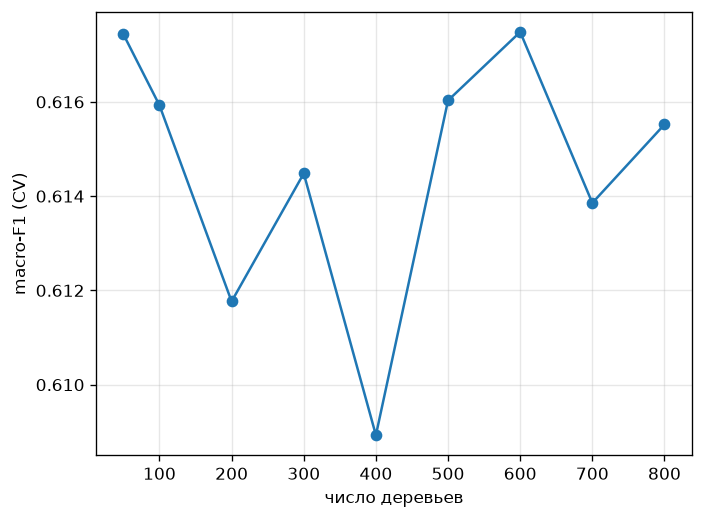

In [14]:
display(Image(filename=str(RES / "rf_n_estimators.png")))

In [15]:
N_TREES = 500       # выбрано по графику выше
print(f"Лучшее число деревьев: {N_TREES}")

Лучшее число деревьев: 500


# 4. Итоговая модель

СV лучшей модели, записываем метрики в общую таблицу. Обучаем на всём train и сохраняем `artifacts/hw2_random_forest.joblib`.

In [16]:
cv_saved.round(3)     # общая таблица CV: старые модели и случайный лес

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
hw2_random_forest,0.618,0.684,0.609,0.781,0.640,0.597,0.573,0.747,0.776,0.539,0.478
hw1_tfidf_logreg,0.583,0.704,0.560,0.783,0.621,0.637,0.607,0.740,0.830,0.596,0.243
hw1_kirp_model,0.564,0.701,0.542,0.777,0.609,0.637,0.588,0.731,0.843,0.616,0.196
hw1_bow_logreg,0.529,0.656,0.516,0.703,0.514,0.585,0.505,0.710,0.803,0.374,0.239
hw1_stratified,0.348,0.467,0.349,0.513,0.339,0.329,0.357,0.607,0.584,0.109,0.104
hw1_most_frequent,0.248,0.593,0.333,0.500,0.333,0.000,0.000,0.593,1.000,0.000,0.000


In [17]:
best_old = old_cv["macro_f1"].max()
forest = cv_saved.loc["hw2_random_forest", "macro_f1"]
print(f"лес: {forest:.3f} | лучшая старая: {best_old:.3f} | разница: {forest - best_old:+.3f}")

лес: 0.618 | лучшая старая: 0.583 | разница: +0.034


## Шаг 5. Важность признаков (MDI)

MDI показывает, насколько признак в среднем уменьшал неоднородность узлов по всем деревьям.

In [25]:
pd.read_csv(RES / "rf_mdi_top15.csv", index_col=0).head(15)

,0
all_tfidf__00,0.000106
all_tfidf__000,0.000055
all_tfidf__01,0.000182
all_tfidf__04,0.000024
all_tfidf__10,0.002190
all_tfidf__100,0.000392
all_tfidf__1000,0.000117
all_tfidf__11,0.000573
all_tfidf__12,0.000819
all_tfidf__13,0.000719


permutation_importance пока считать не стал - 2020 признаков считаются оверхдохрена времени

## Шаг 6. Test — запускать один раз

Test нельзя использовать для выбора параметров. Эту ячейку запускаем **один раз**, когда модель окончательно готова.

In [26]:
pd.read_csv(RES / "test_table.csv", index_col=0).round(3)      # test: старые модели и лес

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
hw2_random_forest,0.637,0.712,0.622,0.795,0.640,0.635,0.564,0.758,0.820,0.581,0.481
hw1_tfidf_logreg,0.593,0.727,0.559,0.776,0.642,0.692,0.564,0.738,0.882,0.750,0.231
hw1_kirp_model,0.581,0.724,0.547,0.781,0.639,0.685,0.570,0.731,0.879,1.000,0.192
hw1_bow_logreg,0.494,0.654,0.484,0.676,0.493,0.608,0.486,0.702,0.811,0.242,0.154
hw1_stratified,0.324,0.452,0.324,0.493,0.331,0.277,0.291,0.606,0.586,0.091,0.096
hw1_most_frequent,0.252,0.606,0.333,0.500,0.333,0.000,0.000,0.606,1.000,0.000,0.000


### матрица ошибок

In [27]:
pd.read_csv(RES / "rf_confusion_matrix.csv", index_col=0)

,предсказано negative,предсказано neutral,предсказано positive
факт negative,101,73,5
факт neutral,51,291,13
факт positive,7,20,25
